# Task 4 — Choose a chart for each car question

Completed Week 1 assignment. Every chart is followed by its design justification and interpretation.

**Run:** Python 3 with `pandas`, `numpy`, `matplotlib`, `seaborn`, and `IPython`. Use **Restart Kernel and Run All**. The original CSV is embedded, so no network or extra data files are needed.

**Data source:** [mpg.csv](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv), downloaded 30 September 2026 using the assignment script's source URL. These are historical teaching datasets, not current-world estimates.

**Chart policy:** finding-led titles, no dual y-axes, zero-based bars, meaningful colour and selective labels. The deliberately messy Task 2 chart is the required counterexample.

In [1]:
import base64, zlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
def finish(fig, note):
    fig.text(0.01, 0.012, note, fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.065, 1, 0.96))
    plt.show()

# Compressed CSV snapshot from the source linked above.
# Replace df with pd.read_csv("data/mpg.csv") to use your local assignment file.
CSV_B64 = (
    'eJyVXMu247hunfsrNEv3iutcvkXO8idZsq3yUZdsOZJ8HvX1IQG+JddNBt1VvVoQSRDY2NikfHtcj+fvcbhf+nk5XoblMXbn/tbf'
    '1+P7NC/9Y/rs5+NnP1zf12N3PvdjP3frMN2Pt+nSj//93XfzcZqH63A/3rtbf6D6jRz1kZPW/kk5sf/mkogjZfZvLTk+l+54fu8/'
    '5mns18b9rR/Hvrl143B6HqhEa+nsqHL/xZXhR0rfZLA+PYfzr2b59T1286+GMxLHhD8p2HLBlbOKYz7G79v0XN+bpVvtiMNqp6r8'
    'VEVuxoupdrdzM/enfmyWZT3Q1lu4J6hAC2GOlKTp/ZzmS7Nal9ynsBzBjHveuOkJLqh7nhTPX7ux+xr6RhK7GoFG0v3JGAEjKY5m'
    'z4HD7WFNow1MicGwglN21Gle0QE/n/N3MwxDGkjCQGAkmCxm95ju69Cdm3O32h26d3GHDOwQ/JtrSfKRnM+626lblu4yzc3lMUYr'
    'zZ1Vi1GheDHUZbpcexsRnY2H+7Wfm6UPU+QC4wHsFDFHvbOx/3F+XrrGPhrdTkja2FZR60G59eDNrtAO283jtOcRTrQqponh1y+r'
    'jaPms7tO9+av5fPvA3O2Ns6pW6KBF/CWHWEu1vSf7tHdj+v0Pa1dc57m6d7ZoLcBbDeCuXBSPkDQVLs4lDu7d3kuaz9jyDsTFxXG'
    'hSVrW1GYuG2wOXzv1wOj8DQDh2gYQOr2CAmQh+Gt++hnu7wDa2Ex8GKtIaa4i3h8O67l0q3L8948RknJgalkINzfqebSDogG/XOe'
    'Hv3xYxp/LdZl/b2xbqKNBZDnV2/3+dLdDxh/1n8wR1iRcv5ri1c8+ue1n1abKCJ6HKAGIpGJbJbeontehoYS0oxLHAMyPuyRrMdY'
    'uu7UGNOHRVFwH24sYxywLH/+dPtsrGtZcLPfFJiQEjqGQNiU69zfbC4dcKUuoFPSKiqPEIX5tvxkksSnYbW4k8JGdfF2F9XfzdlB'
    'Is0gkVF8Wlt38hQgmHAX+66DyZHQuIWKltuns6x+t160j17+GBt0NzY0uhGSGN1i/eJjlVbp+NFfu4ZxO6cYECmhGNPeO3QvoYIJ'
    '5JH1kXB7gU9HXz6G+2oT3WBCcAByglvldpanx4utUvg8DECJxFJhijVsK0xztsk63bBsWGusajAa58y88MCmJprMGhzObQEqjLOa'
    'gyVEb5bHmdaFjVvezaK6hegIs1nZFczCLFbCeoJVzUGUbbF8uH2lmU+q8tGc5ul5fe9uaUjILQkhR6XwAUr/WBrzQi+IUcW27dQ5'
    'lhcfDVZGymKimAu2FnTnCfEc3pmWB1ati6jMJzDB8/S8r3ao5X+ew9zvGjvfSBv/hXHwzdL97ObB2/mNk7BASFtmFCu8knC9WR7T'
    'vHYnu1xfg1iWaS0DRCS6SIIq03DUPMJiuITaVc72p13jaZgvaaopLKnLCFHt383mQHe/Hhj3YAq7oTCdSUxn9/ytn89u087dwzrE'
    'gk3CDkhAxA7KeLTyCGz/GRtLRsgBCKc4tkiWACldWTQ4qaqIWLwLBrCAFmZFlIyr8AY/h2616CdOB07x/YD0AAZty6ODN5g0jh2g'
    '5oEjMsGeKGCDivIj+LAGTXg+B1moD7aeijjOtp4CG7dVlcZKTIMHqIt1rMRVhpxdrXf0YEtdWBvQgu1Sl/duvqzTIyKuq6Dab486'
    'AuBZy4zWTeOajHhanGe5NvMZx+G2i1u/H33DD0iFizrio1uGwcroxoJcx5xyvCdapKLQzM875FLI3hIO29DD1CP9AQ4tMy6MXrLp'
    'HNCoJU6Upxm+JO4ldrp6wtNQW+wMvUvW7QDBommoirlDy4NEAlsYRiAdFee+t2JF3lo+azFwqfwHZFpIwopVIY0e+6U7zalQssLx'
    '4A4hVWE4jZflNp0GWyBtyNuI1LqZp+9u7CvUNWjOmOdrYd/m78U2sc29/3ToibYIgRwTBuk0d6SG5xlw637bBmP+Yg7yH33cvNyj'
    '2pTDZVW2qAx5f2xLWKA1dWxFLnCe7nbQealekvpQu0HCE/o8AObuHogBWu5V0LYthn9JZLIalVgxVBnDucfMPH8/poYK2Ze1CcwQ'
    'aSWlHgL3sl5Q6i1DFqfOwLQm5v22M/BmHghVgFxGtanHm/t79xwduFezTIjBjdw6FhEDTXRCMwPeAKrlIbCAdsuGvQ3PloTxJomK'
    'LkyI+9x0i+WgoHwg7iKl3sNdtNjSdkIiFO5XLkVIGXAyAzcwB8ThWUaf+/vqsIDLRNf2IYdvaWgxigCWbZwvs1Gyxt3T4zAI5AKH'
    'VRLBvC/5bi7s4S5vXRqwZBQcaJ3vMrFAqELRMbJcUgWHGect8AmTDxgz21sfsKCzncFo8Xg4J+8g6qOY5DSUzDuw0HG97Oa57XUL'
    'r5SFBdyDrXiYZ64mtVx6zOcbHG2+p/mX/WtaqPdSriwZSYsXeB1l7M/rbDs+JqOL/TpVijXbuZbGVaFKA3tSmvdp1NmqnWV/2ADq'
    '7mts7gr66/iP3tuW+/TRxalu+ywLwwEu0lS9DLNDmUk1uUqG4W+1MGSIKF5fC0NbIcZIt4losUXZxVYy68C+X10BpdsANSZUh9oT'
    'gfiw3EjBwIaoIpfyRqneYBhFSVEEcuKoWHmW5+k5nyqCgK2cnWExVkYQPobFwdlsszBpZsVutdp41Ey7FZp+zzczxGRYduDpEjFt'
    'B3dPfLPov6ivVLX7kKH6egPEygAX5m4QHxJF9VDUd/aBp3i+HZpmHnnKF/AUjqwmVjPUuyjxsg6vqlmUryQmD1Ql0bJi98sW7UPF'
    'eNNvSduRvnXgdf+EDWtFnzK0t3SevUL7JNM2S5DuMeYYsiiXspmjA9d2uGZXOA9fB4buUIjaEEGqjbtTzlWnrgiyTSIU6npp0Hre'
    'LIx0sT8Bf0H/Zfv45L5KjxyXtD0Zk9JqM0RgUqLfbRg4dwmQgaPX9bo5Vq2wFD8Qyl2K1FPzwqcFAliKCwVAEIYzI20VaD74g4wd'
    'NMcsOblCQYjsJOd0gwQgNcTZCGU+AcQ+xOVqtp0XKrgkPF5C6J7SZwj1GCo2EC23tYBzVQxQ1oIoCcBAbUBchAlRZvCJJancJyW2'
    'sZIWK86SkiNAZIKDttNBPBd/EByCeopQhJK/YC/WAVC0VwZbTV+YVCplYinhLUnBsiSF+WKa/B05307FBmlkLwBSQ7L0J4u413SG'
    'l3VC1J2wiSogCvZX9qdYgEzQrsQOmx2fX8/ldQclZEgN8ZI6ltb5fBXXRTj+uXPLyLRgblyZxt10mx7xsE3A8wtqom9zRPo5fYXI'
    'zCNZ8TjAljtcuuW9ohytRkAm0ZlbnAwJ48wk+EGJNKk9Xd8nAaxAAbASwvdTrE0HDiaFPmWy2N3UHAVszB8mul50KgpqUxSYUDHc'
    '6nq3nhP2plZPRNIRJv8+3W3JPg8fNoPCEEgJYNO4oXFGaGD5UDc/t9jjRNMYTPlsvuibiWAIyYZgCycxuJhddlxTXY8OeAIiTWFb'
    'AWOBpcCGuLBIgNgly1bJ7vJ8ft8zgZoLJVruwXtOBAKXdCWUJouXqlvOPIQI5bBeizv874Y5Qk2R+KjcyI33kHW4xqpS6wQqaBEw'
    'skVB3+aPiniq1NzYwps7rYCmGraxXXKcXafX42L68cWFiwquWx7Kl/wzXGMEtU7kzB4v2spYrPMFER7iP1/Q8uv7vfv8hYxAW4LC'
    'kgVzbRKvF+R54W/bPv4nq0QxQD5OVTjEyoMHTyTg5N1k0IXJ39IY03vVNUo3gN2Iqcqtp61G8ZyavG3pBy1Trug58rcjmErDis0M'
    '4dwt6zxFeOFAOkGwaqPUurOE7JQUhgA0ZSwUXPkHmA98OF05kELGhW9QOFxRgCHweaNFkS65o0w2KdRveRszcjupuTudhrWkd3gb'
    'hVFa7IZz76M7uxV459IYvEwZEUNxS9ALmQ5bQOMyty0MijsJucpp0ELIuOiC0TMhLmMkap6b46zaFO4bbs796Yl7XuJ9GhPuMMht'
    'PWnOH+dzPEeDrg51TRHP4FVZtzhNZ++AeT5GoLCY7PF07FawTRRBJXaO8DykLHSMLueyjhEKlwUTmH8bHs2rc+vnTWO2MTz85tlE'
    'koq7jgfwhMMBYJReHKfS95Xq/8Nj65MZQ4q3lDQviVDSTwCYGkMMx0Pc6I3q9F1mwh6LE2ZvOjy/4bD+zlDgzRj5eGlIBKON0hWM'
    '8lrBZZDua9dAEYesj1eHKMA3hT5CFXNLmpWTYsqMJFoWBvnNJEx70CZg5Yy4e0Psjb3YqnXt3ZxkiCAVxW9rRLdGn9N0+X6NLiyL'
    'oo/PgCovUwxcu0PZyHYzlKQ7Qd0tDye69SWfAqDn0lI2fzpS7nlnB7q+D90BykDcP99cod4Y/RXKwwfwg65Z/sGMCEXe99juUmWb'
    '4iuCZHP51+jcJWNZhKjUDOKxcNcGjANNl8nLLmNaXFLZCf9gGVHPyq+E1WR+rsuvgqnlEptUkNxlPGblV/hzNko8oXRZhhtT4bGM'
    'JCLXV4yAtGfbtJrGbu6bh63dg/Xch06KTlJ4bTl2u5rjZl4wfAHzSgvBisFJROZ9pUXBhlJQsjzCaMTnfFmOXfeXfvlx6u+/G6bJ'
    'gpaVgMo1XExJydNdBuvqsw3TD/uXfu9cRhAZjrZTxn03Z1f3Cx6GN4B1S3yZzbbop13ursNbGS7B5alzoe4eBc1SH5xFXPwDPWqL'
    'zOzOZxCdXfXjQZmDKkJioAmXAG3GQaGiDcvz99NfTjzwrCdGkgypoF24tXX9kc11hYouo8CDlAwaYomTLEKom+fps7kuDnJklTuY'
    '2DotzOfOzx+UNO/den4/da4FKusdNgC4pXG8P5wq4bUAphKkCKJCA9DWot35uTpDd2xgo76PtQ63D0ODYr60wby4W5VXyTpMBDPS'
    'c4a2VJutTZcf87RbHJQY/2Jnyf7s/ACXYGIv4ntYJj2tyePA3y4vG+YA7Jx4YG934SA1zGmOBgGeycKvOcBXnSxmJnAu6jKzfaFp'
    'N+M/cQ9k1gNTBcd1O97IhfTRvqZ7hhcU9yZ4BPzwAn/e57JqOsX5hrYWgI/zQHWzBa7vT/d1AVwaK/otjVFOosmrwpLJ2JBYMCTS'
    '8VYEuaP0kM0TN6A/aigUKhRtFCQxS8lViajj8HOF9ArZjP0e8FXAJ5mwo+oqoRvlJAMq4K1Ehr5kE6CB2HgQyOQ60sJQpswlONW/'
    '/esWgA2viaFip2VMg1wqamyrEeaUhDpgtAID7HXj56+nw3EiNnKapo0usEm7qk49/uWnDYR4PhsHctemOSMDPs8Rl/3jLQuXb9rq'
    '8s0PcRDcTtiTOaHDouEtrf53QdRchn7pR4frNO4PXlhH0VK4l6QaNbib/o7ZaFcF3NMoWRpUPeDpfIbX8RxLh/vfOaTb3SS+dOjt'
    'wUBz/YqzAtGExFmpfJxNb2enYSoI5zwewumXEN6N0z3DVDfbhOReCZKe+ei8EA+PcbLNi8NTlkE4KC6yDRut9xQ+z2ONNayAWHJw'
    'aBwrZPLjfervCHQBvwGnPI+VIY/1/vUQmGP56YNRIX3zje6G2UFj81f3XKe/XdrTlPY6BqWsAyTa3br733GKecEQWDDSysqCgZ6v'
    'NYzSxNFzKGMOQ4kNoMp5QOGyJZWnF7bnOA/d6Cx16QsOEQmssdyu3/3j/RvkPpWW4xsOBkHclkEBjY17niY5EYmpoDA3urMWaDZg'
    '0yv+AlWZ727rTvlyxTg6BD8aEwJeIEqHzP21G/ND6OYv66DT9DdOvApli9iuhrJyv5+uq4qkK8sWQXTgPbljbt31/rw1Dg88WCfu'
    '6rsduV1m6nVbBFOePlmReHLLEiRU+p4LnFKo8wcy7QZ43PcZdl4GNBaZymP8oiNfynS7A1rTekI0cOl6Qv04nC0mrlk55Tg53+9I'
    'LOKyCMLsvO9h92pyRjoVfvxASgZNYQNwFrBnd029Wb6cpal8IUggmZUvbF78cCbkjR9d9GB+QRnW2JGZrMCATChJuFnrujFQCvCr'
    'Mc+BVVmRXJOpxHV0TlS16AcSg0QvlKLfdYSPFVkaBASKkFk6switpSJiGUO3pPHa+FtoyEWxkPwy0HmYJ9s3RQEgC1UOe6TqOuTb'
    'rPELy3hS+vF0SUgPmaYA9bG3aLm4+yN2Y3SNz4Z4TDc7mNQoR0h4hc0ahQYebEpsFrEM5BgbKaDZ4tLohiFb8OOKeDeYjaqj0h1r'
    'sPCtryCFC/7Yiqn6AKNlAceydY3rJWJf6OfB6RzaDPi2hW/9h11DvKStEXYRwTi2jRjmrFzdsr455BxAPTD1xW6uQkSZ/F7f5vvI'
    '2KVgvwBSEZFwHlDu2u73NFgjGHJcTDFFpNcUaseWUm68tSzTpbNC2Mne4HucsbeUeXJa6+e9+a84I3gRp4AoeU6xIFeYjZQYWhcu'
    'ADVBecdrHAaZPfg6v7eVE0iHBvklX2oQaUW5Qf7jCi8IxG6pBfqJGIOih4oyTAr55THMdp54EiEc8EHn0bZIyhxrdbXb1KJSA6IS'
    'hy8CC30Id8cQ4gVTU4pK/XiZ5u4yxTIlaPAkd+0Ig0Jidg9XeEZ0MYkFI14tNv9HnssFDksSLWeEFAkT68/7NA+/p7uzkZUNqIhZ'
    '2Nc2zXrmLlZ06ABg1xlhxLNcUxUfV4hbwDVk/3hjnYe6bYozmmWdnSgcdlrjTkNqmbTTKu10+dH8ONyGtb84Qw1HdDyVIWmA9fAd'
    'vBpW+PTftdMbsxYbPLOzEXDRK9sAnnXxOFuJ33iwukx47n8QmeqHnw5QIdAxmuzI9xqTDcQbzBsF13m1e3y33V9dVI+uz4tdod9n'
    '5pU7vfvbBdC1YyCn3GYEL9mINJzfZZ59DlvslkYeuB0k87moax52kzRYFTXPiSW8HIa7SzOQzZrUFc8hLE0H+1jrNEWir0ld61xG'
    '8EpKwO9LdbYjQJEEfMZnkMAhacQWn9Lo2L0vzCJj5BQXwjY32TJbbL4VUwfuTwyR8eEdXO4PeevtkIWQyplHBv1WyEQOpF/EzUEo'
    'IHLZ3lNs3Uw9N4vrDvJMTX6j7FB4GQ4/BanhA15u8vlk8CH8nkRdhBHURXazpLGFEbWQv52iIkpLp+QxXluiIJTsuMKKgZc88Igf'
    '7z6aOgwcU14yS6/Ig6YElpzhPfU8gKoDDGFrjV2kihgJbMD9+gTleW7nConFaWJ973xpgi/xxwmALqaxgoY/9ra5jBUYG4+kr1ng'
    'kXiXMY6W9DUf5Yg7QOI08t98nI9pe2rWpsMcjt9TUYLy7WafNfnxG9qaNlwD97dKXCUEyb+Ku/nrRwsHDOGeAYsAIonvzNPs1nl4'
    '3h7vzTq3QTvl2KoA8Li7sxIpWw46Qfs8T6cZxDIR7xrgER0L54DVHmH3EKkAzFHDLXhhCHZDuvpode79WTZmnu8JwUZxr316m1LL'
    'Z9I3kSoCg2Ih9/KvwLvZBmnx0x4cj9t8vfMKJejjKpjuQHaI8WxV/oNQ83JV3EAByo6bWukPKHT1fbFrc+14B+6P0CGT4MoB3IjO'
    '/JA+prD19+EiAcpjEhlb7GpoGqNIIfdrDJwlwPc3DZXEI+RoFC4lIgIn2EKua3BCNWw1t8fVmbRF5jAifUNXLztUapEppVEE9vdV'
    'NoqscM+3kcIpfxXWCwG1mwKFAysR+2As7eG4XWffuPfL2UlK4tNBgCkNnDRnS1e7Z8Dew1UDTy0hSLwoD0Nse/R/LOfoEiPFrOTM'
    'KwHJJN6J0YMbpE0ZiZWNptDPt/xhI/F56VMSp2LIJcEDyXpLQjHkLBNbwq9qBG1os/W2Hny54q5ScU9ZrPOdT8Wdaa/Kxp6GM2xR'
    'RLb01DPIpQGBL6r+BLFWyMAkOcXDTlV6+yOaQFcU4RkCjBkku2rribm3LecFrs2weGaCq8Njfb7jCu2yoPsabvA9kKivSwoq4+Zu'
    '738CDsbmC+XgNhw0eoudrmhcKmkcP0dTkHW0CNZ4BWVEiSKwRFSQhfLCUATCqomG/iv9kEMqP9DAg+c3nz137saSO3pqt1bCn6G8'
    'tELoPnCxsYVPeaF4v7RlPy7TNIeL1d4YSWcbMr/8mP8fd+e6WfqMSfpjzhz5JQvoxDalZunjQrOmoOXlZOumKNzHzO7caRWAn207'
    'giBdh0uNMJS7jOt/HUKzuimAM8NwGz3ikwVa4knN3mfbnl2OoQwkhLbNr1fcNNsgtD+dG4Pnc2BvCUq9L80OXGezRHT3V/7b6L4a'
    '3W/wUSDPbyOSaNji8nL5bPy+fzXJIdmdUKq8Wh4neB+WxX1Oa1nR765J10gKBCaysio4UQhfkmbGRKAC+x9sBzdk5NifdZF6ELy3'
    '5i9sbZ9vd58PZ2M7w5iUG3XD6841GV4zpzo7Evb3W2KwVl/ceImC+3tyKiYiJ9TfOtabX4QI6Ha2qdylbiN8UpFRP6mT93dh69Zf'
    'unGE1tvfmsQ73P4zPV5GVwGUY3AsFelWtsJbajubFw5JYpDkhLH1EmUBG5bHze4X8mzDuoccJnKnLczdunmKNigm4KVx5NuqWFDg'
    '9a5/8p/JwG+2gAucNsUEWqQW8WE38fmIDsiWwlBYUuVSZstILW7E+oBEAMQvFS5a5VOyLr72GT5DlYP5tCitiXzV383yw3bG/wtz'
    'WLeZ'
)
df = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(CSV_B64))))
assert len(df) == 398
print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().rename("missing rows").to_frame())

Shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


,missing rows
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
name,0


In [2]:
assert df.horsepower.isna().sum()==6
assert df[['mpg','weight','model_year','origin','cylinders']].isna().sum().sum()==0
df['year']=df.model_year+1900
print('Horsepower is unused: retain all 398 cars in every chart.')
yearly=df.groupby('year').agg(mean_mpg=('mpg','mean'),mean_weight=('weight','mean'),n=('mpg','size'))
display(yearly.round(2))

Horsepower is unused: retain all 398 cars in every chart.


,mean_mpg,mean_weight,n
year,,,
1970,17.69,3372.79,29
1971,21.25,2995.43,28
1972,18.71,3237.71,28
1973,17.10,3419.02,40
1974,22.70,2877.93,27
1975,20.27,3176.80,30
1976,21.57,3078.74,34
1977,23.38,2997.36,28
1978,24.06,2861.81,36


## 1. Did fuel efficiency improve?

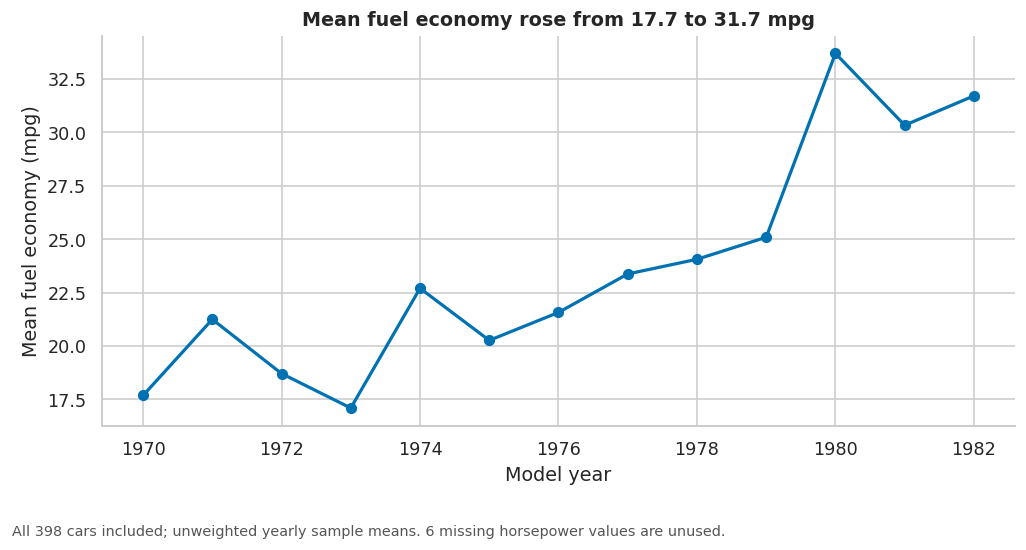

In [3]:
fig,ax=plt.subplots(figsize=(9,5))
ax.plot(yearly.index,yearly.mean_mpg,marker='o',color=BLUE,lw=2)
ax.set(title=f'Mean fuel economy rose from {yearly.mean_mpg.iloc[0]:.1f} to {yearly.mean_mpg.iloc[-1]:.1f} mpg',
       xlabel='Model year',ylabel='Mean fuel economy (mpg)')
ax.set_xticks(yearly.index[::2])
finish(fig,'All 398 cars included; unweighted yearly sample means. 6 missing horsepower values are unused.')

**Why a line:** Ordered model years make a line suitable for seeing the direction of change in yearly mean mpg. Efficiency improved overall but did not rise every year; annual samples differ in size and composition.

## 2. Do origins differ in fuel efficiency?

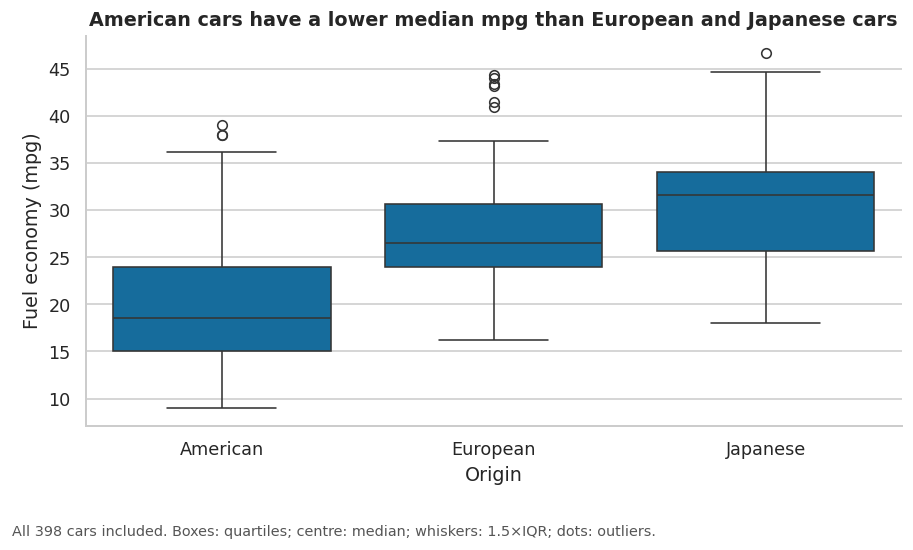

In [4]:
origin_order=['usa','europe','japan']
fig,ax=plt.subplots(figsize=(8,5))
sns.boxplot(data=df,x='origin',y='mpg',order=origin_order,color=BLUE,ax=ax)
ax.set_xticks(range(3),['American','European','Japanese'])
ax.set(title='American cars have a lower median mpg than European and Japanese cars',
       xlabel='Origin',ylabel='Fuel economy (mpg)')
finish(fig,'All 398 cars included. Boxes: quartiles; centre: median; whiskers: 1.5×IQR; dots: outliers.')

**Why boxplots:** Three distributions can be compared by median, spread and outliers rather than only their means. One colour is enough because origin is on the x-axis. Distributions overlap, and origin differences may reflect model year, weight or fleet composition.

## 3. What is the weight–efficiency relationship?

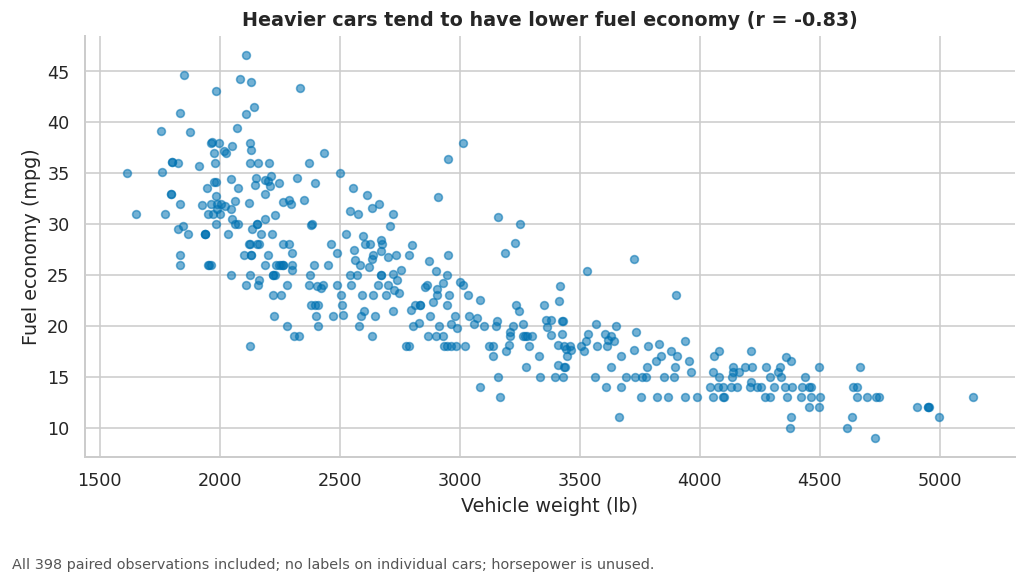

In [5]:
r=df.weight.corr(df.mpg)
fig,ax=plt.subplots(figsize=(9,5.3))
ax.scatter(df.weight,df.mpg,s=24,color=BLUE,alpha=.55)
ax.set(title=f'Heavier cars tend to have lower fuel economy (r = {r:.2f})',
       xlabel='Vehicle weight (lb)',ylabel='Fuel economy (mpg)')
finish(fig,'All 398 paired observations included; no labels on individual cars; horsepower is unused.')

**Why a scatter plot:** Each car contributes two numeric measurements, so points reveal the relationship, scatter and possible nonlinearity. The association is strongly negative, but it does not establish a causal effect or control for engine and year differences.

## 4. How are cylinders distributed?

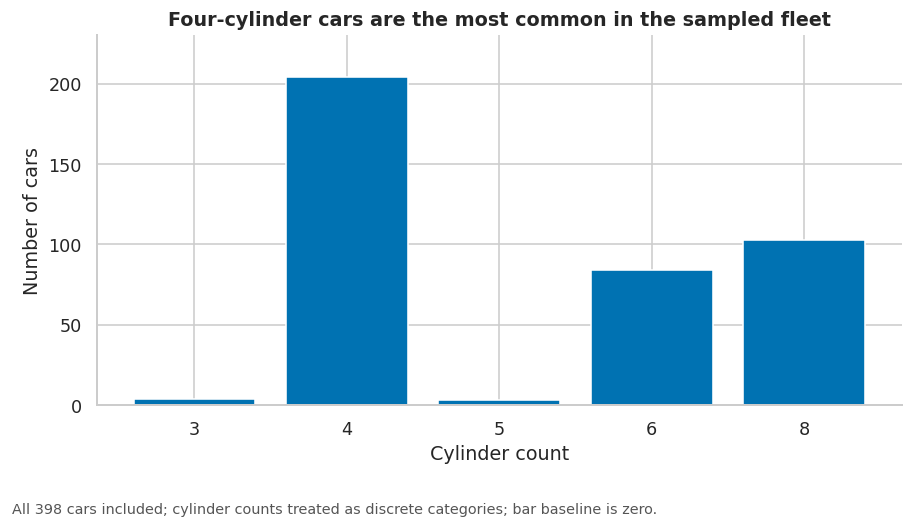

In [6]:
counts=df.cylinders.value_counts().sort_index()
fig,ax=plt.subplots(figsize=(8,4.8))
ax.bar(counts.index.astype(str),counts.values,color=BLUE)
ax.set(title='Four-cylinder cars are the most common in the sampled fleet',
       xlabel='Cylinder count',ylabel='Number of cars',ylim=(0,230))
finish(fig,'All 398 cars included; cylinder counts treated as discrete categories; bar baseline is zero.')

**Why bars:** Cylinders are discrete categories, so separate bars show their counts without implying intermediate values. Four-cylinder cars are most frequent; three- and five-cylinder cars are rare. Numeric ordering preserves the category progression.

## 5. Is the efficiency improvement explained by lighter cars?
Show weight change first, then compare raw yearly mpg with a descriptive weight-adjusted estimate. Fit OLS with year indicators and weight; predict each year at a common **3,000 lb**. This is an exploratory adjustment, not causal mediation.

Descriptive OLS weight slope: -6.38 mpg per 1,000 lb; R²=0.841


,mean_weight,mean_mpg,adjusted_mpg_at_3000lb
year,,,
1970,3372.79,17.69,20.07
1971,2995.43,21.25,21.22
1972,3237.71,18.71,20.23
1973,3419.02,17.10,19.77
1974,2877.93,22.70,21.92
1975,3176.80,20.27,21.40
1976,3078.74,21.57,22.08
1977,2997.36,23.38,23.36
1978,2861.81,24.06,23.18


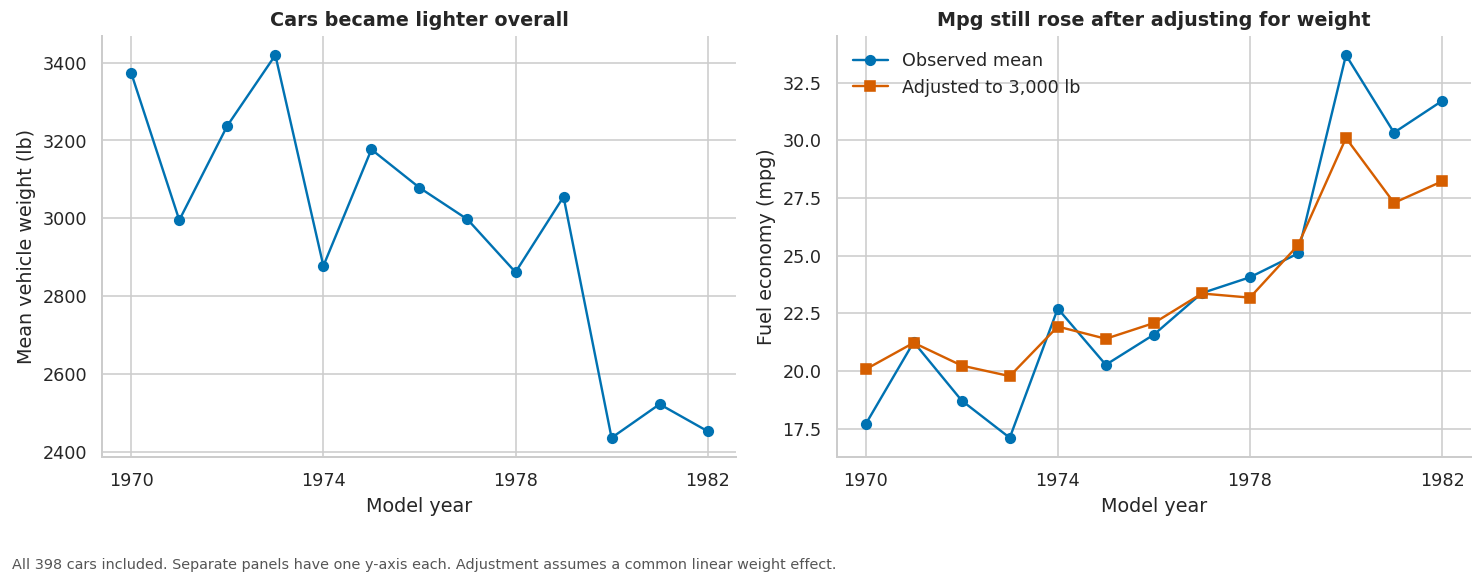

In [7]:
# Linear weight term plus separate model-year effects; no extra package required.
year_dummies=pd.get_dummies(df.year.astype(str),drop_first=True,dtype=float)
X=np.column_stack([np.ones(len(df)),df.weight.to_numpy(),year_dummies.to_numpy()])
beta=np.linalg.lstsq(X,df.mpg.to_numpy(),rcond=None)[0]
reference_weight=3000
prediction=[]
for year in yearly.index:
    dummy=(year_dummies.columns==str(year)).astype(float)
    prediction.append(np.r_[1,reference_weight,dummy] @ beta)
yearly['adjusted_mpg_at_3000lb']=prediction
residual=df.mpg.to_numpy()-X@beta
r2=1-np.sum(residual**2)/np.sum((df.mpg-df.mpg.mean())**2)
print(f'Descriptive OLS weight slope: {beta[1]*1000:.2f} mpg per 1,000 lb; R²={r2:.3f}')
display(yearly[['mean_weight','mean_mpg','adjusted_mpg_at_3000lb']].round(2))
fig,axes=plt.subplots(1,2,figsize=(13,5.3))
axes[0].plot(yearly.index,yearly.mean_weight,marker='o',color=BLUE)
axes[0].set(title='Cars became lighter overall',xlabel='Model year',ylabel='Mean vehicle weight (lb)')
axes[1].plot(yearly.index,yearly.mean_mpg,marker='o',color=BLUE,label='Observed mean')
axes[1].plot(yearly.index,yearly.adjusted_mpg_at_3000lb,marker='s',color=ORANGE,label='Adjusted to 3,000 lb')
axes[1].set(title='Mpg still rose after adjusting for weight',xlabel='Model year',ylabel='Fuel economy (mpg)')
axes[1].legend(frameon=False)
for ax in axes:ax.set_xticks([1970,1974,1978,1982])
finish(fig,'All 398 cars included. Separate panels have one y-axis each. Adjustment assumes a common linear weight effect.')

**Why two aligned line panels:** Yearly trends answer whether vehicles became lighter, while a second panel compares raw and adjusted mpg in the same units. Separating units avoids dual y-axes. Colour in the right panel distinguishes observed from adjusted values.

**Answer:** Falling average weight is consistent with part of the mpg improvement, but it does not account for all of it in this descriptive model: adjusted mpg also rises. This is not proof of how much weight caused the change. The weight effect is assumed linear and constant across years; omitted engine, origin and technology differences, changing samples, and limited weight overlap can affect the result.

## Redraw the weakest chart
The cylinder chart hides exact counts and makes the rare categories harder to compare. Redraw it as frequency-ranked horizontal bars.

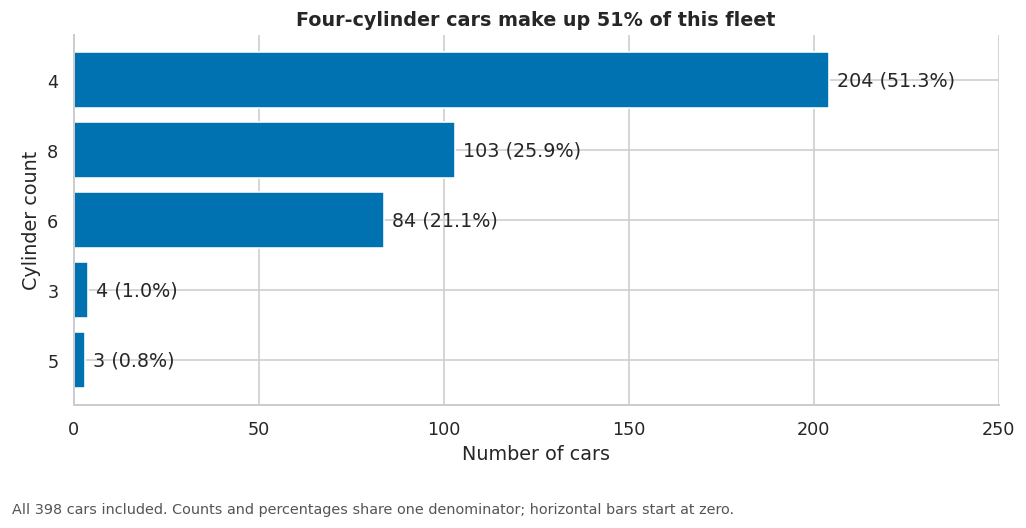

In [8]:
ranked=df.cylinders.value_counts().sort_values(ascending=True)
fig,ax=plt.subplots(figsize=(9,4.8))
bars=ax.barh(ranked.index.astype(str),ranked.values,color=BLUE)
ax.bar_label(bars,labels=[f'{n} ({n/len(df):.1%})' for n in ranked.values],padding=5)
ax.set(title=f'Four-cylinder cars make up {df.cylinders.eq(4).mean():.0%} of this fleet',
       xlabel='Number of cars',ylabel='Cylinder count',xlim=(0,250))
finish(fig,'All 398 cars included. Counts and percentages share one denominator; horizontal bars start at zero.')

**Why this redraw:** Frequency ranking makes the dominant category immediate, horizontal labels stay readable, and five selective count/percentage labels make rare categories explicit. I traded numeric cylinder order for a clearer frequency comparison. No second axis or extra colour is needed.